In [31]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# récupération du dataset nettoyé
df_clean = pd.read_csv("csv/train_clean.csv")

# affichage des premières lignes du dataset
df_clean.head()

,Survived,Pclass,Male,Fare,WithoutFam,Embarked_Q,Embarked_S,Title_Col,Title_Don,Title_Dr,...,Title_Major,Title_Master,Title_Miss,Title_Mlle,Title_Mme,Title_Mr,Title_Mrs,Title_Ms,Title_Rev,Title_Sir
0,0,3,1,7.2500,0,0,1,0,0,0,...,0,0,0,0,0,1,0,0,0,0
1,1,1,0,71.2833,0,0,0,0,0,0,...,0,0,0,0,0,0,1,0,0,0
2,1,3,0,7.9250,1,0,1,0,0,0,...,0,0,1,0,0,0,0,0,0,0
3,1,1,0,53.1000,0,0,1,0,0,0,...,0,0,0,0,0,0,1,0,0,0
4,0,3,1,8.0500,1,0,1,0,0,0,...,0,0,0,0,0,1,0,0,0,0


In [32]:
# Puisque le dataset est déjà nettoyé, on peut directement séparer les features et la target

# Features
X = df_clean.drop(columns=["Survived"])

# Target
y = df_clean["Survived"]


KNN = K-Nearest Neigbors : Les voisins les plus proches. 

--> Modèle de Machine learning supervisé : On entraine notre modèle sur un dataset avec des étiquettes connues (ici Survived ou Dead)

--> Le modèle se base sur ses voisins les plus proches pour faire sa prédiction

--> On peut ajuster la performance du modèle en modifiant le paramètre n_neigbors(k) qui correspond au nombre de voisin les plus proches à prendre en compte. Il faut trouver le bon équilibre entre accuracy  et overfitting : un nombre de voisins trop bas causera une bonne accuracy  sur le train , mais une mauvaise accuracy  sur le test : overfitting . Un nombre de voisins trop important causera un diminution de l'accuracy  

Avant de faire l'entrainement du modèle, j'ai appliqué un standardscaler aux données afin d'équilibrer les poids de chaque variable. Fare étant beaucoup plus important que certaines autres variables, sans Scaler il aura un poids beaucoup plus important sur la prédiction.

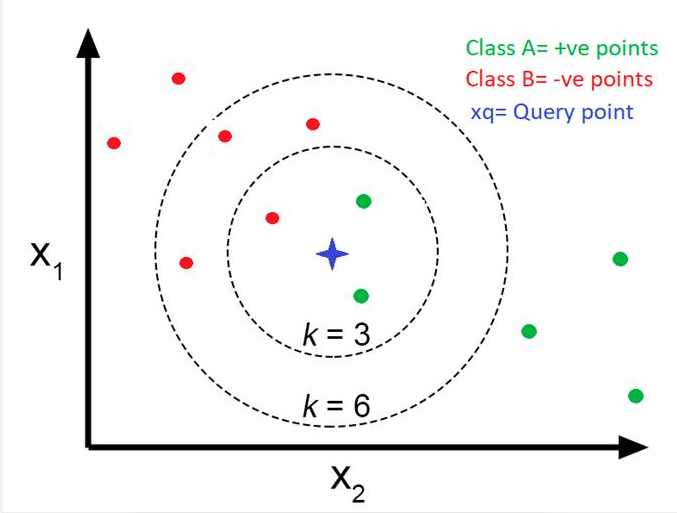 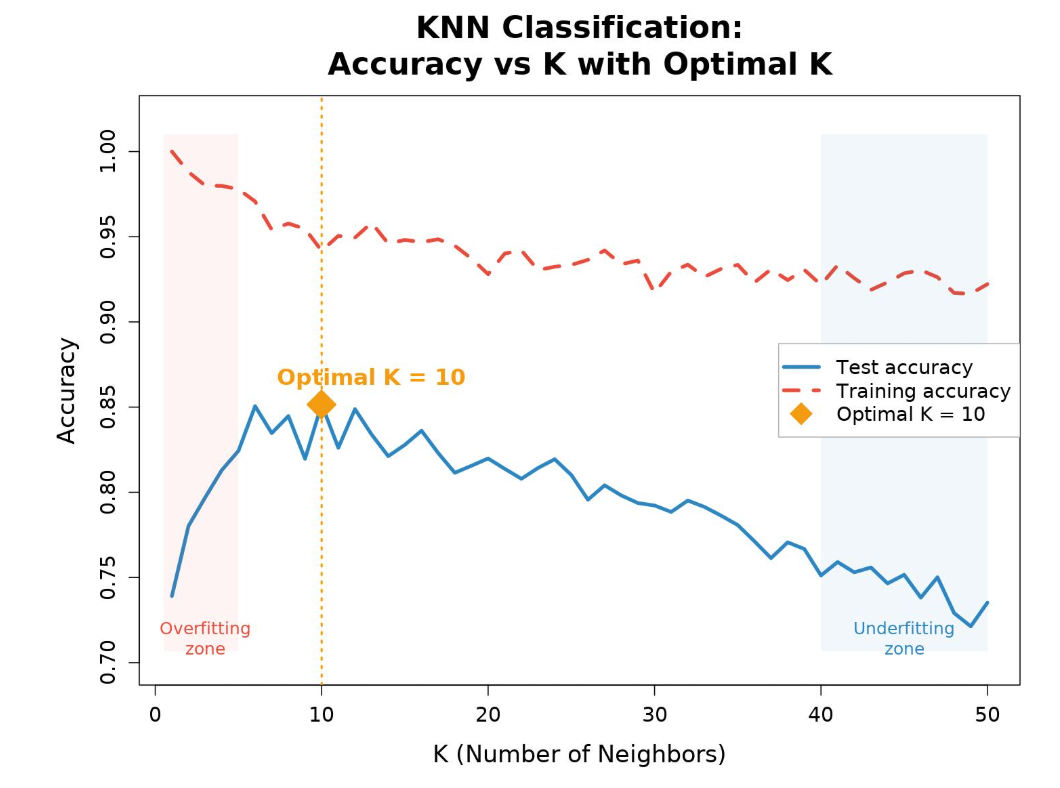

In [33]:
# Division des données en ensemble d'entrainement et de test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Création du scaler afin de normaliser les données (résout le problème de poids des variables)
scaler = StandardScaler()

# Calcul des paramètres sur les données train
X_train = scaler.fit_transform(X_train)

# Application des mêmes paramètres aux données de test
X_test = scaler.transform(X_test)

# Création du modèle KNN avec un argument n_neighbors=7 (nombre de voisins à prendre en compte pour la prédiction)
model_KNN = KNeighborsClassifier(n_neighbors=7)

# Entrainement du modèle
model_KNN.fit(X_train, y_train)

# Test du modèle et récupération des prédictions sur les données test
y_test_pred = model_KNN.predict(X_test)

# Evaluation du modèle
print(f"test score: {model_KNN.score(X_test, y_test)}")
print(f"train score: {model_KNN.score(X_train, y_train)}")
print(f"classification_report:\n{classification_report(y_test, y_test_pred)}")


test score: 0.8033707865168539
train score: 0.8635724331926864
classification_report:
              precision    recall  f1-score   support

           0       0.84      0.83      0.84       109
           1       0.74      0.75      0.75        69

    accuracy                           0.80       178
   macro avg       0.79      0.79      0.79       178
weighted avg       0.80      0.80      0.80       178



Les métriques : 

- Accuracy = les vrais positifs et les vrais négatifs sur la totalité des prédictions : Ici le modèle a fait une prédiction correctre 80 % du temps (143 sur 178) sur le test. Sur les données train, il a une accuracy légèrement plus élevée de 86 %, mais les 2 valeurs sont proches, il n'y pas de surapprentissage important.
- Précision (1) = C'est le nombre de vrais positifs sur la totalité des positifs prédits (vrais positifs + faux positifs) : C'est à dire dans notre cas, si le modèle prédit qu'un passager a survécu, alors il a raison dans 74% des cas
- Recall (1) = C'est le nombre de vrais positif sur le nombre réel de passagers qui ont survécus : Parmi tous les passager qui ont réellement survécus, le modèle en a prédit 75 % correctement
- le f1-score (1) c'est une moyenne entre la précision et le recall: le modèle obtient un meilleur équilibre precision/recall pour les décès (0,84) que pour les survivants (0,75).

La precision, le recall et le f1-score sont calculés pour les survivants (1) et les décédés (0)



La confusion matrix permet de visualiser facilement le nombre de VP, FP, VN et FN

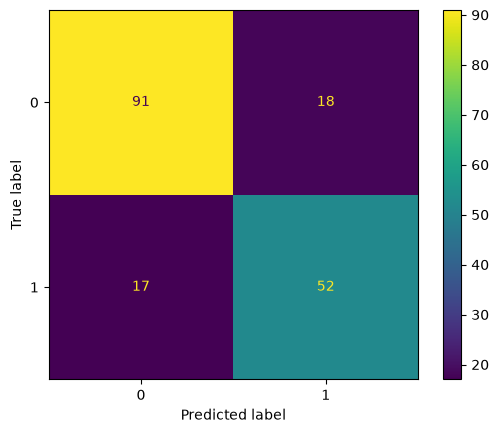

In [34]:
cm = confusion_matrix(y_test, y_test_pred, labels=model_KNN.classes_)
disp = ConfusionMatrixDisplay(cm, display_labels=model_KNN.classes_)
disp.plot()
plt.show()

En conclusion : le modèle présente des performances globalement satisfaisantes, avec 80 % de prédictions correctes.